<a href="https://colab.research.google.com/github/mominanoor/Machine-Learning/blob/main/A01a_linearRegression1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
%%writefile ex1data1.txt
6.1101,17.592
5.5277,9.1302
8.5186,13.662
7.0032,11.854
5.8598,6.8233
8.3829,11.886
7.4764,4.3483
8.5781,12
6.4862,6.5987
5.0546,3.8166
5.7107,3.2522
14.164,15.505
5.734,3.1551
8.4084,7.2258
5.6407,0.71618
5.3794,3.5129
6.3654,5.3048
5.1301,0.56077
6.4296,3.6518
7.0708,5.3893
6.1891,3.1386
20.27,21.767
5.4901,4.263
6.3261,5.1875
5.5649,3.0825
18.945,22.638
12.828,13.501
10.957,7.0467
13.176,14.692
22.203,24.147
5.2524,-1.22
6.5894,5.9966
9.2482,12.134
5.8918,1.8495
8.2111,6.5426
7.9334,4.5623
8.0959,4.1164
5.6063,3.3928
12.836,10.117
6.3534,5.4974
5.4069,0.55657
6.8825,3.9115
11.708,5.3854
5.7737,2.4406
7.8247,6.7318
7.0931,1.0463
5.0702,5.1337
5.8014,1.844
11.7,8.0043
5.5416,1.0179
7.5402,6.7504
5.3077,1.8396
7.4239,4.2885
7.6031,4.9981
6.3328,1.4233
6.3589,-1.4211
6.2742,2.4756
5.6397,4.6042
9.3102,3.9624
9.4536,5.4141
8.8254,5.1694
5.1793,-0.74279
21.279,17.929
14.908,12.054
18.959,17.054
7.2182,4.8852
8.2951,5.7442
10.236,7.7754
5.4994,1.0173
20.341,20.992
10.136,6.6799
7.3345,4.0259
6.0062,1.2784
7.2259,3.3411
5.0269,-2.6807
6.5479,0.29678
7.5386,3.8845
5.0365,5.7014
10.274,6.7526
5.1077,2.0576
5.7292,0.47953
5.1884,0.20421
6.3557,0.67861
9.7687,7.5435
6.5159,5.3436
8.5172,4.2415
9.1802,6.7981
6.002,0.92695
5.5204,0.152
5.0594,2.8214
5.7077,1.8451
7.6366,4.2959
5.8707,7.2029
5.3054,1.9869
8.2934,0.14454
13.394,9.0551
5.4369,0.61705

Writing ex1data1.txt


# 1 Linear Regression with One Variable

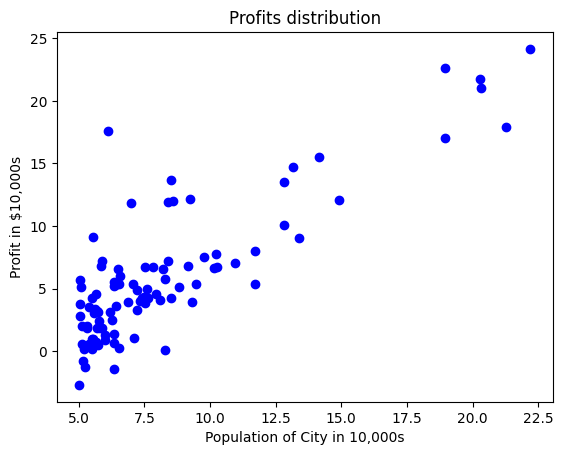

In [2]:
#number of training samples
from numpy import loadtxt, ones, zeros, array, linspace, logspace
import matplotlib.pyplot as plt

# Load the datasets
data = loadtxt('ex1data1.txt', delimiter=',')

# Plot the data
plt.scatter(data[:,0], data[:,1], marker = 'o', c = 'b')
plt.title('Profits distribution')
plt.xlabel('Population of City in 10,000s')
plt.ylabel('Profit in $10,000s')
plt.show()

m = len(data[:,0])
X = ones(shape=(m, 2)) #Add a column of ones to X (interception data)
X[:, 1] = data[:,0]
y = data[:, 1]


In [3]:
#Evaluate the linear regression
def compute_cost(X, y, theta):
    '''
    Comput cost for linear regression
    '''
    #Number of training samples
    m = y.size

    predictions = X.dot(theta).flatten()

    sqErrors = (predictions - y) ** 2

    J = (1.0 / (2 * m)) * sqErrors.sum()

    return J

## Task 1
For following different values of $\theta$ fill the folling table and draw the corresponding hypothesis. For the first $\theta$ values, I have filled the table and also drawn the plots.

 $\theta$ | $J(\theta)$   
 ------   |-------------  
  (10,0) |  23.68             
  (0,1)   |               
  (-5,1)  |               


23.681383361991752


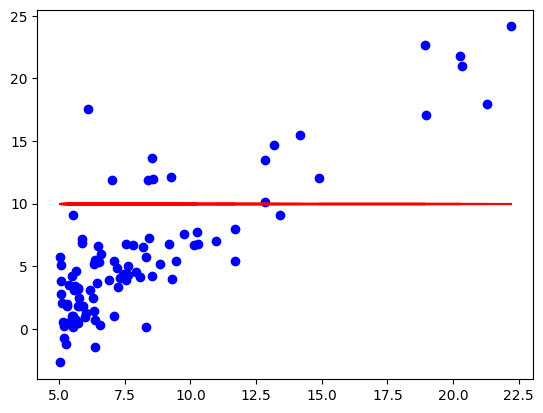

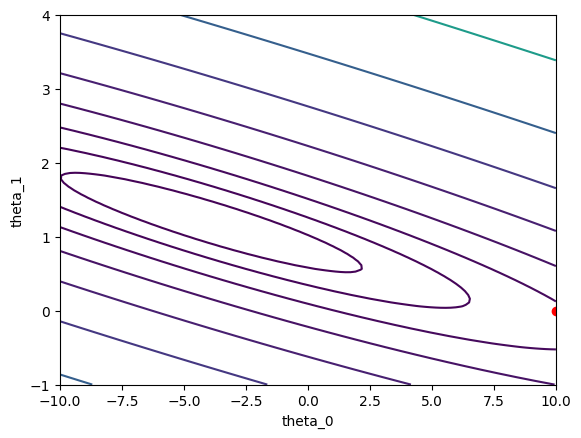

In [4]:
theta = array([10,0])
print(compute_cost(X,y,theta))

#Plot the results
result = X.dot(theta).flatten()
plt.plot(X[:, 1], result, c = 'r')
plt.scatter(X[:,1], y, c = 'b')
plt.show()

plt.figure()
#Grid over which we will calculate J
theta0_vals = linspace(-10, 10, 100)
theta1_vals = linspace(-1, 4, 100)

#initialize J_vals to a matrix of 0's
J_vals = zeros(shape=(theta0_vals.size, theta1_vals.size))

#Fill out J_vals
for t1, element in enumerate(theta0_vals):
    for t2, element2 in enumerate(theta1_vals):
        thetaT = zeros(shape=(2, 1))
        thetaT[0][0] = element
        thetaT[1][0] = element2
        J_vals[t1, t2] = compute_cost(X, y, thetaT)

#Contour plot
J_vals = J_vals.T
plt.contour(theta0_vals, theta1_vals, J_vals, logspace(-2, 3, 20))
plt.xlabel('theta_0')
plt.ylabel('theta_1')
plt.scatter(theta[0], theta[1], c = 'r')
plt.show()

## Task 2

We will use batch gradient descent to minimize the cost function. (Read Lecture_notes1.pdf)
Implement the gradient_descent algorithm (#todo parts of the following function)

In [5]:
def gradient_descent(X, y, theta, alpha, num_iters):
    '''
    Performs gradient descent to learn theta
    by taking num_items gradient steps with learning
    rate alpha
    '''
    m = y.size
    J_history = zeros(shape=(num_iters, 1))

    for i in range(num_iters):

        predictions = X.dot(theta).flatten()
        errors = predictions - y

        #Compute gradient
        grad_x1 = (1.0 / m) * errors.sum()
          #gradient of J with respect to x1
        grad_x2 = (1.0 / m) * (errors * X[:, 1]).sum()
        #gradient of J with respect to x2

        #Update the thetas
        theta[0] = theta[0] - alpha * grad_x1
        theta[1] = theta[1] - alpha * grad_x2

        J_history[i, 0] = compute_cost(X, y, theta)

    return theta, J_history

## Task3

Run the gradient descent algorithm for num_iters = 1500 and the learning rate, alpha=.01.
Initialize the theta to (0,0). Plot the final result

In [6]:
alpha = .01
num_iters = 1500
theta = array([0.,0.])

theta, J_history = gradient_descent(X, y, theta, alpha, num_iters)
print(theta)

[-3.63029144  1.16636235]


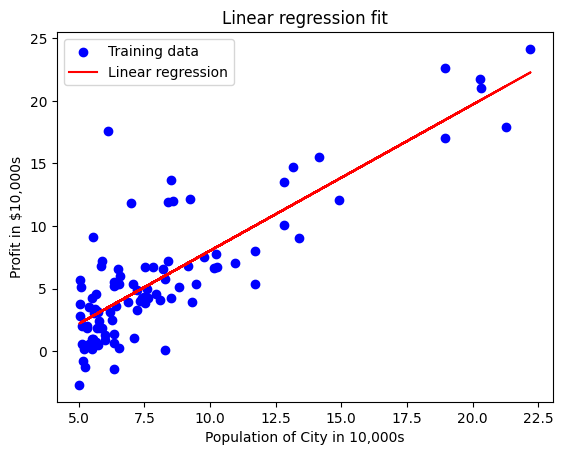

In [7]:
#Plot the results
plt.scatter(X[:,1], y, c='b', label='Training data')
plt.plot(X[:,1], X.dot(theta).flatten(), c='r', label='Linear regression')
plt.title('Linear regression fit')
plt.xlabel('Population of City in 10,000s')
plt.ylabel('Profit in $10,000s')
plt.legend()
plt.show()

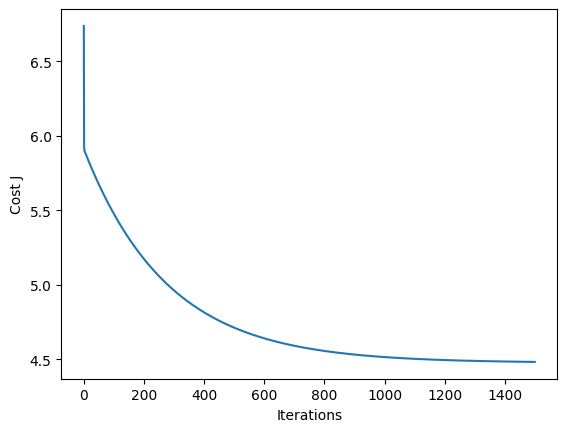

In [8]:
plt.figure()
plt.plot(J_history)
plt.xlabel('Iterations')
plt.ylabel('Cost J')
plt.show()